## 00-EDA Exploratory Data Analysis - 50 / 50 - with filenames

In this notebook, we are going to do EDA (Exploratory Data Analysis) on the train set. We would focus on the text data first.
Because we have more data, so we can split train set to 50-50, to have better dev set for evaluation

In [1]:
# import required packages
import pandas as pd
import os
from wordcloud import WordCloud, STOPWORDS, ImageColorGenerator
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
# labels
# AD = Alzheimer's Disease (positive class)
# CN = Cognitively Normal (negative class)

In [3]:
path_ad = "../data/Transcribed Data-2024-Feb-13/Diagnosis Training Data/ad transcribed/"
path_cn = "../data/Transcribed Data-2024-Feb-13//Diagnosis Training Data/cn transcribed/"

In [4]:
train_data = {"ad":[], 
              "cn":[]
             }

file_names = {"ad":[],
              "cn":[]
             }

In [5]:
def read_data(path):
    """
        get data from "txt" files from a specified folder (ad/cn)
        returns list of text (strings)
    """
    result = []
    filenames = []
    # get only txt files
    files = [item
             for item in os.listdir(path)
             if item.endswith("txt")
            ]
    
    for fname in files:
        print("Processing files =", fname) #, end="\r")
        with open(path + fname, encoding="utf-8") as f:
            lines = f.readlines()
            print("Line len =", len(lines)) #, end="\r")
            text = "\n".join(lines)
            result.append(text)
            filenames.append(fname.replace(".txt", "")) # remove txt extensions

    return (result, filenames)

train_data["ad"], file_names["ad"] = read_data(path_ad)
train_data["cn"], file_names["cn"] = read_data(path_cn)

Processing files = adrso024.txt
Line len = 23
Processing files = adrso025.txt
Line len = 13
Processing files = adrso027.txt
Line len = 9
Processing files = adrso028.txt
Line len = 17
Processing files = adrso031.txt
Line len = 29
Processing files = adrso032.txt
Line len = 5
Processing files = adrso033.txt
Line len = 7
Processing files = adrso035.txt
Line len = 9
Processing files = adrso036.txt
Line len = 21
Processing files = adrso039.txt
Line len = 9
Processing files = adrso043.txt
Line len = 27
Processing files = adrso045.txt
Line len = 35
Processing files = adrso046.txt
Line len = 13
Processing files = adrso047.txt
Line len = 3
Processing files = adrso049.txt
Line len = 15
Processing files = adrso053.txt
Line len = 21
Processing files = adrso054.txt
Line len = 21
Processing files = adrso055.txt
Line len = 9
Processing files = adrso056.txt
Line len = 29
Processing files = adrso059.txt
Line len = 3
Processing files = adrso060.txt
Line len = 19
Processing files = adrso063.txt
Line len =

In [6]:
# double check data
assert len(train_data["ad"]) == 87
assert len(train_data["cn"]) == 79
assert train_data["ad"][0].startswith("The cookie jar and the little")
assert train_data["ad"][1].startswith("Tell me everything that's going on")
assert train_data["cn"][0].startswith("Okay, I see a mom doing")
assert train_data["cn"][1].startswith("Starting from the left I see")
print("Passed")

Passed


In [7]:
# assert filenames
assert file_names["ad"][0].startswith("adrso024")
assert file_names["ad"][1].startswith("adrso025")
assert file_names["ad"][-1].startswith("adrso253")

assert file_names["cn"][0].startswith("adrso002")
assert file_names["cn"][1].startswith("adrso003")
assert file_names["cn"][-1].startswith("adrso316")

print("Passed")

Passed


In [8]:
# take a look at the data
print(train_data["ad"][0][:100])

The cookie jar and the little



boy about down on the floor



girls



Girls anyway the housewife



In [9]:
# take a look at the data
print(train_data["cn"][0][:100])

Okay, I see a mom doing the dishes and the waters overflowing from the sink and she seems to be comp


In [10]:
print(file_names["ad"][0:5])

['adrso024', 'adrso025', 'adrso027', 'adrso028', 'adrso031']


In [11]:
print(file_names["cn"][0:5])

['adrso002', 'adrso003', 'adrso005', 'adrso007', 'adrso008']


In [12]:
# build word-clouds
def make_wordcloud(text_list):
    """
    display a wordcloud based on the text list
    parameters:
        text_list: list of text (paragraphs)
    returns:
        list of frequent words        
    """
    text = "\n".join(text_list).lower()
    wordcloud = WordCloud().generate(text)

    # process text and return counts of frequent words
    result = sorted(WordCloud().process_text(text).items(), 
                    key=lambda item: item[1],
                    reverse=True
                   )
    
    
    plt.imshow(wordcloud)
    plt.axis("off")
    plt.show()

    return result

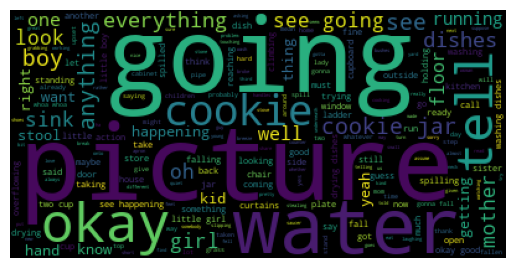

[('picture', 102), ('going', 100), ('water', 98), ('okay', 80), ('tell', 69), ('cookie', 63), ('cookie jar', 59), ('see', 58), ('boy', 57), ('anything', 56), ('everything', 52), ('dishes', 52), ('mother', 46), ('sink', 45), ('look', 44), ('see going', 42), ('girl', 41), ('oh', 41), ('one', 38), ('floor', 36), ('well', 36), ('running', 33), ('happening', 32), ('kid', 30), ('hand', 28), ('right', 27), ('know', 26), ('getting', 25), ('yeah', 24), ('want', 24), ('stool', 24), ('thing', 23), ('see happening', 23), ('trying', 22), ('fall', 22), ('something', 21), ('window', 21), ('think', 21), ('washing dishes', 21), ('falling', 20), ('say', 18), ('now', 18), ('plate', 17), ('action', 17), ('little girl', 17), ('okay good', 17), ('still', 16), ('go', 15), ('washing', 15), ('chair', 15)]


In [13]:
# see the most frequent words of AD (positive) group
ad_top_words = make_wordcloud(train_data["ad"])
print(ad_top_words[:50])
ad_top_words_set = set([w
                        for w, count in ad_top_words[:200]
                       ])

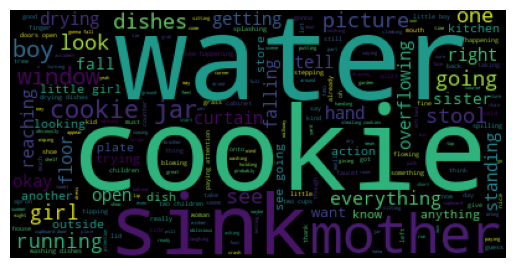

[('water', 102), ('cookie', 97), ('sink', 85), ('mother', 75), ('cookie jar', 75), ('boy', 71), ('window', 69), ('stool', 54), ('see', 53), ('picture', 53), ('going', 53), ('one', 52), ('look', 52), ('dishes', 51), ('girl', 46), ('running', 46), ('everything', 45), ('okay', 41), ('reaching', 40), ('getting', 38), ('tell', 38), ('floor', 37), ('hand', 35), ('drying', 34), ('overflowing', 33), ('right', 32), ('curtain', 31), ('standing', 30), ('open', 29), ('falling', 28), ('fall', 26), ('sister', 26), ('want', 24), ('little girl', 24), ('action', 23), ('plate', 22), ('anything', 21), ('see going', 21), ('know', 20), ('looking', 20), ('kitchen', 20), ('trying', 20), ('outside', 19), ('dish', 19), ('another', 19), ('store', 19), ('washing dishes', 18), ('onto', 17), ('thing', 17), ('little boy', 17)]


In [14]:
# see the most frequent words of CN (negative) group
cn_top_words = make_wordcloud(train_data["cn"])
print(cn_top_words[:50])
cn_top_words_set = set([w
                        for w, count in cn_top_words[:200]
                       ])

In [15]:
# observe the difference in 2 word set
ad_unique = ad_top_words_set - cn_top_words_set
cn_unique = cn_top_words_set - ad_top_words_set
print("AD unique words =\n", ad_unique)
print("----------------")
print("CN unique words =\n", cn_unique)


AD unique words =
 {'assume', 'suppose', 'stealing', 'guy', 'small', 'rather', 'underneath', 'taken', 'lady', 'pretty', 'find', 'problem', 'upset', 'hard', 'us', 'whatever', 'fell', 'curtains', 'spilled', 'watching', 'stand', 'home', 'whether', 'young', 'made', 'lot', 'pipe', 'slipping', 'spill', 'whoa whoa', 'cup', 'stove', 'new', 'eat', 'read', 'touching', 'call', 'next', 'grabbing', 'put', 'wash', 'different', 'saucer', 'broke', 'love', 'okay good', 'ladder', 'given', 'gotta', 'two cup', 'neck', 'handles', 'try', 'always', 'breeze', 'break', 'almost', 'third', 'told', 'sorry', 'yes', 'cooking', 'ha', 'telling', 'stone', 'step', 'working', 'bushes', 'somebody', 'goes', 'share', 'shoes'}
----------------
CN unique words =
 {'shelf', 'curtain', 'tipping', 'start', 'paying', 'flowing', 'giving', 'path', 'place', 'letting', 'part', 'obviously', 'faucet', 'come', 'wind', 'handing', 'mouth', 'nothing', 'even', 'towel', 'tilting', 'mama', 'turning', 'though', 'oblivious', 'full', 'crash', '

We can see that there are some words that are common in both categories (AD/CN):
- cookie, cookie jar, water, sink, look, etc

Some words that frequently appear in AD (positive) group, but not so frequently in CN (negative) groups:
- ladder, lady, stone, scaucer, somebody, whatever, guy

These words tend to be generic (not very specific)

Some words that frequently appear in CN (negative) group, but not so frequently in AD (positive) groups:
- dress, left hand, faucet, tipping

These words tend to be more specific and detailed. 

In [16]:
# combine data into a dataframe, for export to a csv for further processing
train_dict = {
    "file_id": [],  #  file name
    "text": [],    # the transcript
    "target": []   # the target: positive (AD), negative (CN)
}
for item, fname in zip(train_data["ad"], file_names["ad"]):
    train_dict["file_id"].append(fname)
    train_dict["text"].append(item)
    train_dict["target"].append("AD")

for item, fname in zip(train_data["cn"], file_names["cn"]):
    train_dict["file_id"].append(fname)
    train_dict["text"].append(item)
    train_dict["target"].append("CN")

print("Text count =", len(train_dict["text"]))
print("Target count =", len(train_dict["target"]))
print("File_id count =", len(train_dict["target"]))

Text count = 166
Target count = 166
File_id count = 166


In [17]:
train_df = pd.DataFrame(train_dict)
print(len(train_df))
train_df.head()

166


,file_id,text,target
0,adrso024,The cookie jar and the little\n\n\n\nboy about...,AD
1,adrso025,Tell me everything that's going on\n\n\n\nthe ...,AD
2,adrso027,As a picture little girl and a little boy stan...,AD
3,adrso028,She will find her mother worship trying to dis...,AD
4,adrso031,What do you see going on\n\n\n\nthe boys on a ...,AD


In [18]:
train_df.describe()

,file_id,text,target
count,166,166,166
unique,166,166,2
top,adrso024,The cookie jar and the little\n\n\n\nboy about...,AD
freq,1,1,87


We can see we have total of 166 examples, with 87 positive (AD) and 79 negative (CN). The train_set is relatively balanced. 

Now we can split the data into train and dev set

In [19]:
train_set_df = train_df.sample(frac=0.5, random_state=42)
print(train_set_df.describe())
train_set_df.head()

         file_id                                               text target
count         83                                                 83     83
unique        83                                                 83      2
top     adrso021  Everything you see going on in this picture, g...     AD
freq           1                                                  1     47


,file_id,text,target
100,adrso021,"Everything you see going on in this picture, g...",CN
136,adrso265,"Now you just look at the picture. Okay, this i...",CN
78,adrso237,Tell me everything that you see going on in th...,AD
56,adrso197,Girls and boys getting her one that stores sto...,AD
97,adrso017,"All right, we have a few more tasks to go thro...",CN


In [20]:
dev_set_df = train_df.drop(train_set_df.index)
print(dev_set_df.describe())
dev_set_df.head()

         file_id                                               text target
count         83                                                 83     83
unique        83                                                 83      2
top     adrso025  Tell me everything that's going on\n\n\n\nthe ...     CN
freq           1                                                  1     43


,file_id,text,target
1,adrso025,Tell me everything that's going on\n\n\n\nthe ...,AD
3,adrso028,She will find her mother worship trying to dis...,AD
5,adrso032,What's going on well the children are climbing...,AD
7,adrso035,Okay here's the picture tell me I'll tell you ...,AD
8,adrso036,Tell me what's going on\n\n\n\nall the action ...,AD


In [21]:
# make sure there's no overlap between train and dev set
for filename in train_set_df["file_id"]:
    if filename in dev_set_df["file_id"]:
        print("Duplicate detected")
    assert filename not in dev_set_df["file_id"]

print("Passed")

Passed


In [22]:
# write to csv
path = "../data/splits/"

In [23]:
train_set_df.head()

,file_id,text,target
100,adrso021,"Everything you see going on in this picture, g...",CN
136,adrso265,"Now you just look at the picture. Okay, this i...",CN
78,adrso237,Tell me everything that you see going on in th...,AD
56,adrso197,Girls and boys getting her one that stores sto...,AD
97,adrso017,"All right, we have a few more tasks to go thro...",CN


In [24]:
dev_set_df.head()

,file_id,text,target
1,adrso025,Tell me everything that's going on\n\n\n\nthe ...,AD
3,adrso028,She will find her mother worship trying to dis...,AD
5,adrso032,What's going on well the children are climbing...,AD
7,adrso035,Okay here's the picture tell me I'll tell you ...,AD
8,adrso036,Tell me what's going on\n\n\n\nall the action ...,AD


In [25]:
print("Writing to csv files...")

train_set_df.to_csv(path + "train_50pc.csv",
                   index=False)
dev_set_df.to_csv(path + "dev_50pc.csv",
                 index=False)
print("Completed")

Writing to csv files...
Completed
